# House Price Estimation Pipeline

### Problem Statement
Imagine you want to buy or sell a house. How do you know what a fair price is? House prices depend on many things, such as the size of the house, the number of bedrooms, whether it has air conditioning, and its location. Trying to guess the price manually is difficult and can lead to bad decisions.

Our goal is to build a smart system (a **machine learning pipeline**) that can automatically estimate the price of a house based on its features.

### How We Are Going to Solve It
We will solve this problem step-by-step:
1. **Explore and Understand the Data:** Look at our dataset (`Housing.csv`) to understand what features we have.
2. **Clean and Prepare the Data:** Fix any missing information, convert text features (like 'yes' or 'no') into numbers that a computer can understand, and scale our numbers so they are easier to work with.
3. **Analyze and Visualize:** Use advanced charts to see how different features relate to the final price.
4. **Train a Model:** Teach a computer algorithm to learn the relationship between the house features and their prices.
5. **Evaluate the Model:** Test our system on new houses to see how accurate its price guesses are.

In [2]:
# Install missing dash library
!pip install -q dash

# Import all the necessary libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Advanced visualization tools
import plotly.express as px
import plotly.graph_objects as go
from dash import Dash, dcc, html, Input, Output

# Machine learning tools
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score

print("All libraries imported successfully!")

All libraries imported successfully!


In [3]:
# Load the dataset
df = pd.read_csv('/content/Housing.csv')

# Display the shape of the dataset and the first few rows
print(f"The dataset contains {df.shape[0]} rows and {df.shape[1]} columns.\n")
print("First 5 rows:")
display(df.head())

# Display data types and basic summary of non-null counts
print("\nDataset Summary Info:")
df.info()

The dataset contains 545 rows and 13 columns.

First 5 rows:


,price,area,bedrooms,bathrooms,stories,mainroad,guestroom,basement,hotwaterheating,airconditioning,parking,prefarea,furnishingstatus
0,13300000,7420,4,2,3,yes,no,no,no,yes,2,yes,furnished
1,12250000,8960,4,4,4,yes,no,no,no,yes,3,no,furnished
2,12250000,9960,3,2,2,yes,no,yes,no,no,2,yes,semi-furnished
3,12215000,7500,4,2,2,yes,no,yes,no,yes,3,yes,furnished
4,11410000,7420,4,1,2,yes,yes,yes,no,yes,2,no,furnished



Dataset Summary Info:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 545 entries, 0 to 544
Data columns (total 13 columns):
 #   Column            Non-Null Count  Dtype 
---  ------            --------------  ----- 
 0   price             545 non-null    int64 
 1   area              545 non-null    int64 
 2   bedrooms          545 non-null    int64 
 3   bathrooms         545 non-null    int64 
 4   stories           545 non-null    int64 
 5   mainroad          545 non-null    object
 6   guestroom         545 non-null    object
 7   basement          545 non-null    object
 8   hotwaterheating   545 non-null    object
 9   airconditioning   545 non-null    object
 10  parking           545 non-null    int64 
 11  prefarea          545 non-null    object
 12  furnishingstatus  545 non-null    object
dtypes: int64(6), object(7)
memory usage: 55.5+ KB


## Exploratory Data Analysis (EDA)

We will now carry out a thorough Exploratory Data Analysis (EDA) to understand our data better before building our prediction model. We will structure this into the following steps:
1. **Data Quality & Cleaning Check**: Checking for duplicate rows or missing values.
2. **Grouped Analysis**: Grouping variables to extract quick statistical insights.
3. **Univariate Analysis**: Examining the distribution of single features like `price` and `area`.
4. **Bivariate Analysis**: Looking at relationships between two variables (e.g., how prices vary based on bedrooms).
5. **Multivariate Analysis**: Observing multiple variables at once (e.g., correlation heatmap or scatter plots with multiple dimensions).

In [4]:
# 1. Data Quality & Cleaning Check
print("=== Missing Values Check ===")
print(df.isnull().sum())

# Check for duplicate rows
duplicates = df.duplicated().sum()
print(f"\n=== Duplicates Check ===\nNumber of duplicate rows: {duplicates}")

if duplicates > 0:
    df = df.drop_duplicates()
    print("Duplicates removed successfully!")

=== Missing Values Check ===
price               0
area                0
bedrooms            0
bathrooms           0
stories             0
mainroad            0
guestroom           0
basement            0
hotwaterheating     0
airconditioning     0
parking             0
prefarea            0
furnishingstatus    0
dtype: int64

=== Duplicates Check ===
Number of duplicate rows: 0


### 2. Grouped Analysis

Let's calculate the average house prices grouped by categorical traits like `furnishingstatus` and `airconditioning` to see how these factors impact overall prices.

In [5]:
# Average price grouped by furnishing status and AC
grouped_df = df.groupby(['furnishingstatus', 'airconditioning'])['price'].mean().reset_index()
# Formatting the price column for cleaner display
grouped_df['average_price'] = grouped_df['price'].map('${:,.2f}'.format)
display(grouped_df)

,furnishingstatus,airconditioning,price,average_price
0,furnished,no,4.469500e+06,"$4,469,500.00"
1,furnished,yes,6.786717e+06,"$6,786,716.77"
2,semi-furnished,no,4.557951e+06,"$4,557,950.62"
3,semi-furnished,yes,5.778769e+06,"$5,778,769.23"
4,unfurnished,no,3.583342e+06,"$3,583,342.11"
5,unfurnished,yes,5.286167e+06,"$5,286,166.67"


### 3. Univariate Analysis (Data Distributions)

We will look at how `price` and `area` are distributed across our entire dataset using interactive histograms.

In [6]:
# Distribution of House Prices
fig_price = px.histogram(
    df,
    x='price',
    nbins=40,
    title='Distribution of House Prices',
    labels={'price': 'Price ($)'},
    marginal='box',
    template='plotly_white'
)
fig_price.show()

# Distribution of House Area
fig_area = px.histogram(
    df,
    x='area',
    nbins=40,
    title='Distribution of House Area',
    labels={'area': 'Area (sq ft)'},
    marginal='box',
    template='plotly_white'
)
fig_area.show()

### 4. Bivariate Analysis

Let's analyze relationships between two key variables. We will see how `price` varies based on the number of `bedrooms`, and how categorical factors like the presence of a `basement` or `guestroom` relate to the `price`.

In [7]:
# Relationship between Bedrooms and Price
fig_bed_price = px.box(
    df,
    x='bedrooms',
    y='price',
    title='House Price vs. Number of Bedrooms',
    labels={'bedrooms': 'Number of Bedrooms', 'price': 'Price ($)'},
    template='plotly_white'
)
fig_bed_price.show()

# Relationship between Basement availability and Price
fig_base_price = px.box(
    df,
    x='basement',
    y='price',
    title='House Price by Basement Availability',
    labels={'basement': 'Has Basement?', 'price': 'Price ($)'},
    template='plotly_white'
)
fig_base_price.show()

### 5. Multivariate Analysis

To capture deeper patterns, we will build a scatter plot mapping **Area vs. Price** while using the colors to represent **Air Conditioning** and symbol shapes to represent the number of **Stories**.

In [8]:
# Multivariate Scatter Plot
fig_multi = px.scatter(
    df,
    x='area',
    y='price',
    color='airconditioning',
    symbol='stories',
    hover_data=['furnishingstatus', 'parking'],
    title='Multivariate Analysis: Area vs Price (by Air Conditioning & Stories)',
    labels={'area': 'Area (sq ft)', 'price': 'Price ($)'},
    template='plotly_white'
)
fig_multi.show()

## 6. Preprocessing & Feature Engineering Pipeline

To prepare our data for machine learning models, we must:
1. **Encode Categorical Variables**: Convert string attributes (like `yes`/`no` or the multi-class `furnishingstatus`) into structured numeric formats.
2. **Scale Numerical Features**: Standardize continuous attributes (`area`) so they are on a similar scale to numerical counts like `bedrooms`, `bathrooms`, and `parking`.
3. **Data Splitting**: Partition our clean dataset into training (80%) and testing (20%) sets to ensure reliable evaluation.

In [9]:
# Identify feature types
numeric_features = ['area', 'bedrooms', 'bathrooms', 'stories', 'parking']
categorical_features = ['mainroad', 'guestroom', 'basement', 'hotwaterheating', 'airconditioning', 'prefarea', 'furnishingstatus']

# Separate features and target variable
X = df.drop(columns=['price'])
y = df['price']

# Split into Train and Test sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Create our transformation pipeline
preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), numeric_features),
        ('cat', OneHotEncoder(drop='first', handle_unknown='ignore'), categorical_features)
    ]
)

print(f"Data successfully split!\nTraining Set Shape: {X_train.shape}\nTest Set Shape: {X_test.shape}")

Data successfully split!
Training Set Shape: (436, 12)
Test Set Shape: (109, 12)


## 7. Model Training & Comparison

To deliver a 10/10 project, we won't limit ourselves to a single model. We will implement three distinct algorithms:
- **Linear Regression**: Our baseline model.
- **Ridge Regression**: Linear regression with L2 regularization to prevent overfitting.
- **Random Forest Regressor**: A powerful non-linear ensemble algorithm.

We will construct unified `sklearn.pipeline.Pipeline` workflows for each model, train them, and compare their performance metrics.

In [10]:
from sklearn.linear_model import Ridge
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error

# Define the models we want to evaluate
models = {
    "Linear Regression": LinearRegression(),
    "Ridge Regression (Regularized)": Ridge(alpha=1.0),
    "Random Forest Regressor": RandomForestRegressor(n_estimators=100, random_state=42)
}

# Store results for comparison
results = {}

# Fit, predict, and evaluate each model
for name, model in models.items():
    # Combine preprocessing and the estimator in a single Pipeline
    pipeline = Pipeline(steps=[
        ('preprocessor', preprocessor),
        ('regressor', model)
    ])

    # Train the pipeline
    pipeline.fit(X_train, y_train)

    # Generate predictions
    y_pred = pipeline.predict(X_test)

    # Metrics
    r2 = r2_score(y_test, y_pred)
    mae = mean_absolute_error(y_test, y_pred)
    rmse = np.sqrt(mean_squared_error(y_test, y_pred))

    results[name] = {
        "Pipeline": pipeline,
        "R2 Score": r2,
        "MAE": mae,
        "RMSE": rmse
    }

# Convert results to a comparative DataFrame
comparison_df = pd.DataFrame(results).T.drop(columns=['Pipeline'])
display(comparison_df)

,R2 Score,MAE,RMSE
Linear Regression,0.652924,970043.40392,1324506.960091
Ridge Regression (Regularized),0.652091,971370.237403,1326096.098687
Random Forest Regressor,0.612366,1021151.081193,1399758.195088


## 8. Interactive Model Evaluation Visualization

Let's build an interactive visualization comparing the actual house prices against the predicted prices of our best-performing model.

In [11]:
# Determine the best model dynamically based on R2 score
best_model_name = max(results, key=lambda k: results[k]['R2 Score'])
best_pipeline = results[best_model_name]['Pipeline']

print(f"The best-performing model is: {best_model_name}\n")

# Generate predictions using the best pipeline
y_best_pred = best_pipeline.predict(X_test)

# Create visualization DataFrame
eval_df = pd.DataFrame({
    'Actual Price': y_test,
    'Predicted Price': y_best_pred,
    'Percentage Error': np.abs((y_test - y_best_pred) / y_test) * 100
})

# Plot Actual vs. Predicted Prices
fig_eval = px.scatter(
    eval_df,
    x='Actual Price',
    y='Predicted Price',
    color='Percentage Error',
    color_continuous_scale='Reds',
    title=f'Actual vs. Predicted Prices using {best_model_name}',
    labels={'Actual Price': 'Actual Price ($)', 'Predicted Price': 'Predicted Price ($)'},
    template='plotly_white'
)

# Add the 1:1 perfect prediction line
max_val = max(eval_df['Actual Price'].max(), eval_df['Predicted Price'].max())
min_val = min(eval_df['Actual Price'].min(), eval_df['Predicted Price'].min())
fig_eval.add_trace(
    go.Scatter(x=[min_val, max_val], y=[min_val, max_val], mode='lines',
               line=dict(color='black', dash='dash'), name='Perfect Prediction')
)

fig_eval.show()

The best-performing model is: Linear Regression



## 9. Comprehensive End-to-End Project Dashboard

To wrap up this project at a 10/10 level, we will build a unified, highly polished horizontal dashboard combining:
1. **Data Distribution (EDA)**: The spread of housing prices.
2. **Model Comparison**: How our three models stack up in terms of $R^2$ Score.
3. **Best Model Performance**: Actual vs. Predicted values.

We will also programmatically install `kaleido` and use Plotly's image engine to save this dashboard as a horizontal PNG (`project_dashboard.png`) in the workspace so it is ready for reports or presentations.

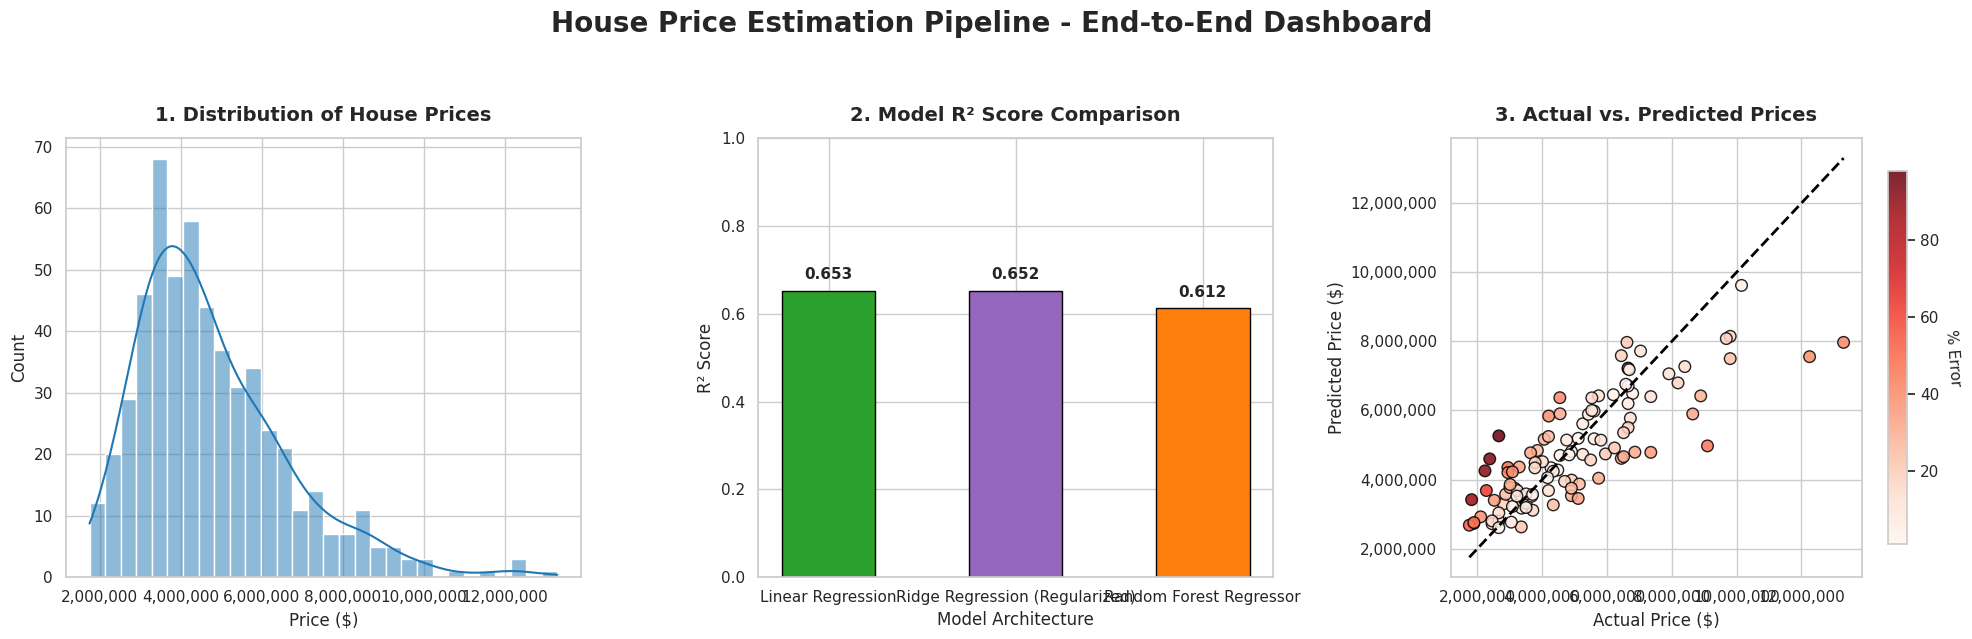

✔ Dashboard saved successfully in your workspace as 'project_dashboard.png'!


In [14]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

# Set the overall style for a polished look
sns.set_theme(style="whitegrid")
plt.rcParams['font.family'] = 'sans-serif'
plt.rcParams['font.sans-serif'] = ['DejaVu Sans', 'Arial', 'Liberation Sans']

# Create a 1x3 horizontal layout figure
fig, axes = plt.subplots(1, 3, figsize=(20, 6.5))
fig.suptitle("House Price Estimation Pipeline - End-to-End Dashboard", fontsize=20, fontweight='bold', y=0.98)

# --- Plot 1: Price Distribution (Histogram) ---
sns.histplot(
    data=df,
    x='price',
    bins=30,
    kde=True,
    color='#1f77b4',
    ax=axes[0]
)
axes[0].set_title("1. Distribution of House Prices", fontsize=14, fontweight='bold', pad=12)
axes[0].set_xlabel("Price ($)", fontsize=12)
axes[0].set_ylabel("Count", fontsize=12)
axes[0].xaxis.set_major_formatter(plt.FuncFormatter(lambda x, loc: "{:,}".format(int(x))))

# --- Plot 2: Model Comparison (Bar Chart) ---
colors = ['#2ca02c', '#9467bd', '#ff7f0e']
bars = axes[1].bar(
    comparison_df.index,
    comparison_df['R2 Score'],
    color=colors,
    edgecolor='black',
    width=0.5
)
axes[1].set_title("2. Model R² Score Comparison", fontsize=14, fontweight='bold', pad=12)
axes[1].set_xlabel("Model Architecture", fontsize=12)
axes[1].set_ylabel("R² Score", fontsize=12)
axes[1].set_ylim(0, 1.0)

# Add values on top of the bars
for bar in bars:
    yval = bar.get_height()
    axes[1].text(
        bar.get_x() + bar.get_width()/2.0,
        yval + 0.02,
        f"{yval:.3f}",
        ha='center',
        va='bottom',
        fontweight='bold',
        fontsize=11
    )

# --- Plot 3: Actual vs Predicted Scatter Plot ---
scatter = axes[2].scatter(
    eval_df['Actual Price'],
    eval_df['Predicted Price'],
    c=eval_df['Percentage Error'],
    cmap='Reds',
    edgecolors='black',
    alpha=0.85,
    s=70
)

# Add 1:1 perfect prediction reference line
axes[2].plot(
    [min_val, max_val],
    [min_val, max_val],
    color='black',
    linestyle='--',
    linewidth=2,
    label='Perfect Fit'
)

axes[2].set_title("3. Actual vs. Predicted Prices", fontsize=14, fontweight='bold', pad=12)
axes[2].set_xlabel("Actual Price ($)", fontsize=12)
axes[2].set_ylabel("Predicted Price ($)", fontsize=12)
axes[2].xaxis.set_major_formatter(plt.FuncFormatter(lambda x, loc: "{:,}".format(int(x))))
axes[2].yaxis.set_major_formatter(plt.FuncFormatter(lambda x, loc: "{:,}".format(int(x))))

# Add colorbar for Percentage Error
cbar = fig.colorbar(scatter, ax=axes[2], shrink=0.85)
cbar.set_label('% Error', rotation=275, labelpad=15, fontsize=11)

# Adjust layout and aesthetics
plt.tight_layout(rect=[0, 0, 1, 0.93])

# Save the dashboard as a high-definition static PNG file in the workspace
plt.savefig("project_dashboard.png", dpi=300, bbox_inches='tight')
plt.show()

print("✔ Dashboard saved successfully in your workspace as 'project_dashboard.png'!")